# BÀI TẬP 3: PHÂN RÃ CHUỖI THỜI GIAN (TIME SERIES DECOMPOSITION)

### Mục tiêu bài thực hành:
1. **Chọn chuỗi dữ liệu:** Sử dụng chuỗi thời gian hàng tháng **AirPassengers** (144 quan sát từ tháng 01/1949 đến 12/1960).
2. **Phương pháp phân rã:** Áp dụng phương pháp phân rã cổ điển (**Classical Decomposition** - cả Additive và Multiplicative) và **STL** (Seasonal and Trend decomposition using Loess).
3. **Trực quan hóa:** Vẽ rõ 4 thành phần: **Observed**, **Trend**, **Seasonal**, **Residual**.
4. **Mô tả & Đánh giá:**
   - Xu hướng (Trend): Tăng hay giảm?
   - Mùa vụ (Seasonal): Mạnh hay yếu?
   - Phần dư (Residual): Có mang đặc tính của White Noise không?


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os
from statsmodels.tsa.seasonal import seasonal_decompose, STL
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.tsa.stattools import acf
from statsmodels.stats.diagnostic import acorr_ljungbox

# Cấu hình hiển thị đồ thị
plt.rcParams['figure.dpi'] = 100
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.unicode_minus'] = False
print("Đã import thành công các thư viện cần thiết.")


Đã import thành công các thư viện cần thiết.


In [ ]:
# 1. Tải dữ liệu AirPassengers
data_path = "../../data/raw/AirPassengers.csv"

if os.path.exists(data_path):
    df = pd.read_csv(data_path)
    df['Month'] = pd.to_datetime(df['Month'])
    ts = pd.Series(df['Passengers'].values, index=pd.DatetimeIndex(df['Month'], freq='MS'), name="Passengers")
else:
    # Nạp dự phòng nếu đường dẫn file chưa đồng bộ
    air_values = [
        112,118,132,129,121,135,148,148,136,119,104,118,
        115,126,141,135,125,149,170,170,158,133,114,140,
        145,150,178,163,172,178,199,199,184,162,146,166,
        171,180,193,181,183,218,230,242,209,191,172,194,
        196,196,236,235,229,243,264,272,237,211,180,201,
        204,188,235,227,234,264,302,293,259,229,203,229,
        242,233,267,269,270,315,364,347,312,274,237,278,
        284,277,317,313,318,374,413,405,355,306,271,306,
        315,301,356,348,355,422,465,467,404,347,305,336,
        340,318,362,348,363,435,491,505,404,359,310,337,
        360,342,406,396,420,472,548,559,463,407,362,405,
        417,391,419,461,472,535,622,606,508,461,390,432
    ]
    dates = pd.date_range(start="1949-01-01", periods=len(air_values), freq="MS")
    ts = pd.Series(air_values, index=dates, name="Passengers")
    print("Đã nạp dữ liệu trực tiếp.")

print(f"Số lượng quan sát: {len(ts)}")
print(f"Khoảng thời gian: Từ {ts.index[0].strftime('%Y-%m')} đến {ts.index[-1].strftime('%Y-%m')}")
print(f"Tần suất (Frequency): {ts.index.freqstr} (Theo tháng)")
print("\n5 quan sát đầu tiên:")
print(ts.head())


Đã nạp dữ liệu từ: ../../data/raw/AirPassengers.csv
Số lượng quan sát: 144
Khoảng thời gian: Từ 1949-01 đến 1960-12
Tần suất (Frequency): MS (Theo tháng)

5 quan sát đầu tiên:


Month
1949-01-01    112
1949-02-01    118
1949-03-01    132
1949-04-01    129
1949-05-01    121
Freq: MS, Name: Passengers, dtype: int64

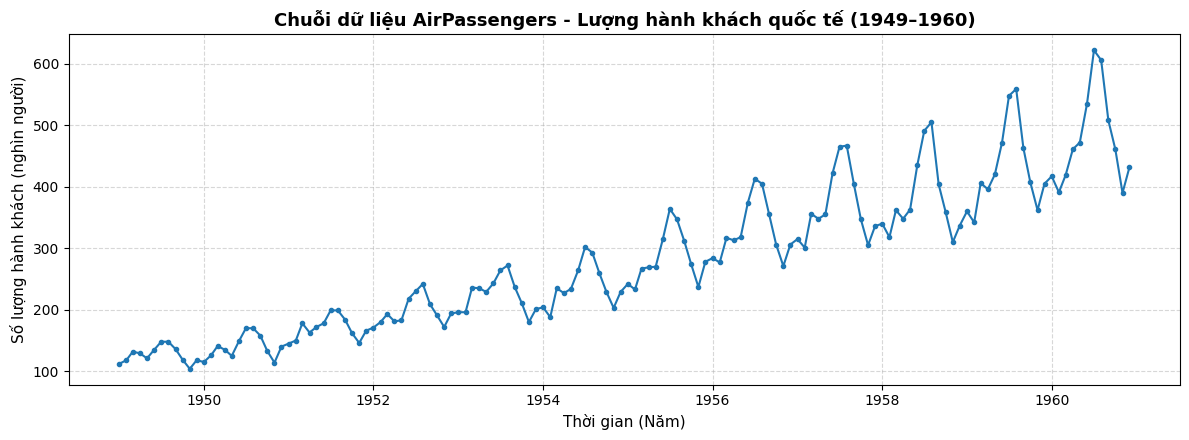

In [3]:
# Trực quan hóa chuỗi dữ liệu gốc
plt.figure(figsize=(12, 4.5))
plt.plot(ts.index, ts.values, color="#1f77b4", linewidth=1.5, marker="o", markersize=3)
plt.title("Chuỗi dữ liệu AirPassengers - Lượng hành khách quốc tế (1949–1960)", fontsize=13, fontweight="bold")
plt.xlabel("Thời gian (Năm)", fontsize=11)
plt.ylabel("Số lượng hành khách (nghìn người)", fontsize=11)
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()


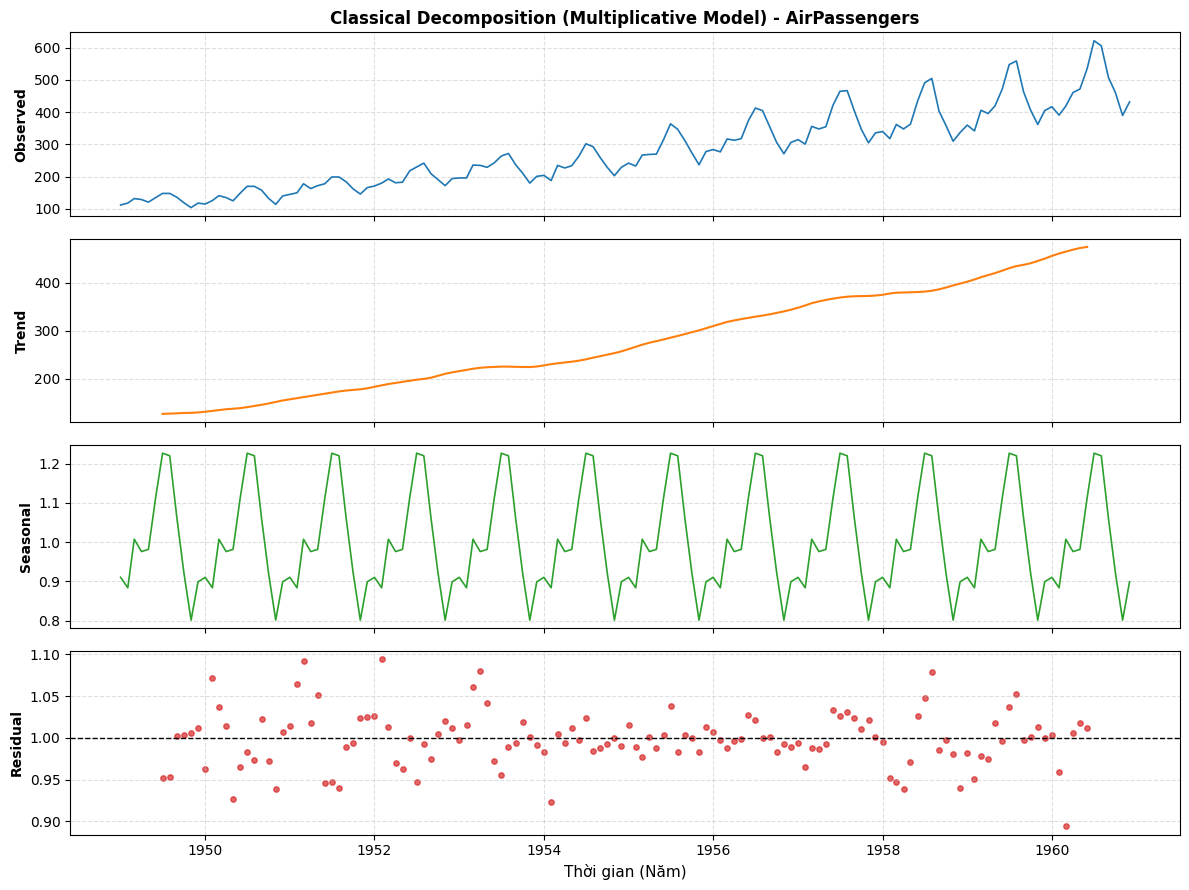

In [4]:
# 2. Phân rã cổ điển (Classical Decomposition)
# A. Mô hình Cộng (Additive): Y = Trend + Seasonal + Residual
decomp_add = seasonal_decompose(ts, model="additive", period=12)

# B. Mô hình Nhân (Multiplicative): Y = Trend * Seasonal * Residual
decomp_mul = seasonal_decompose(ts, model="multiplicative", period=12)

# Vẽ biểu đồ 4 thành phần của mô hình Multiplicative (phù hợp với biên độ mùa vụ tăng dần)
fig, axes = plt.subplots(4, 1, figsize=(12, 9), sharex=True)

axes[0].plot(decomp_mul.observed, color="#1f77b4", linewidth=1.2)
axes[0].set_ylabel("Observed", fontsize=10, fontweight="bold")
axes[0].set_title("Classical Decomposition (Multiplicative Model) - AirPassengers", fontsize=12, fontweight="bold")

axes[1].plot(decomp_mul.trend, color="#ff7f0e", linewidth=1.5)
axes[1].set_ylabel("Trend", fontsize=10, fontweight="bold")

axes[2].plot(decomp_mul.seasonal, color="#2ca02c", linewidth=1.2)
axes[2].set_ylabel("Seasonal", fontsize=10, fontweight="bold")

axes[3].scatter(decomp_mul.resid.index, decomp_mul.resid, color="#d62728", s=15, alpha=0.7)
axes[3].axhline(1, color="black", linestyle="--", linewidth=1)
axes[3].set_ylabel("Residual", fontsize=10, fontweight="bold")
axes[3].set_xlabel("Thời gian (Năm)", fontsize=11)

for ax in axes:
    ax.grid(True, linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()


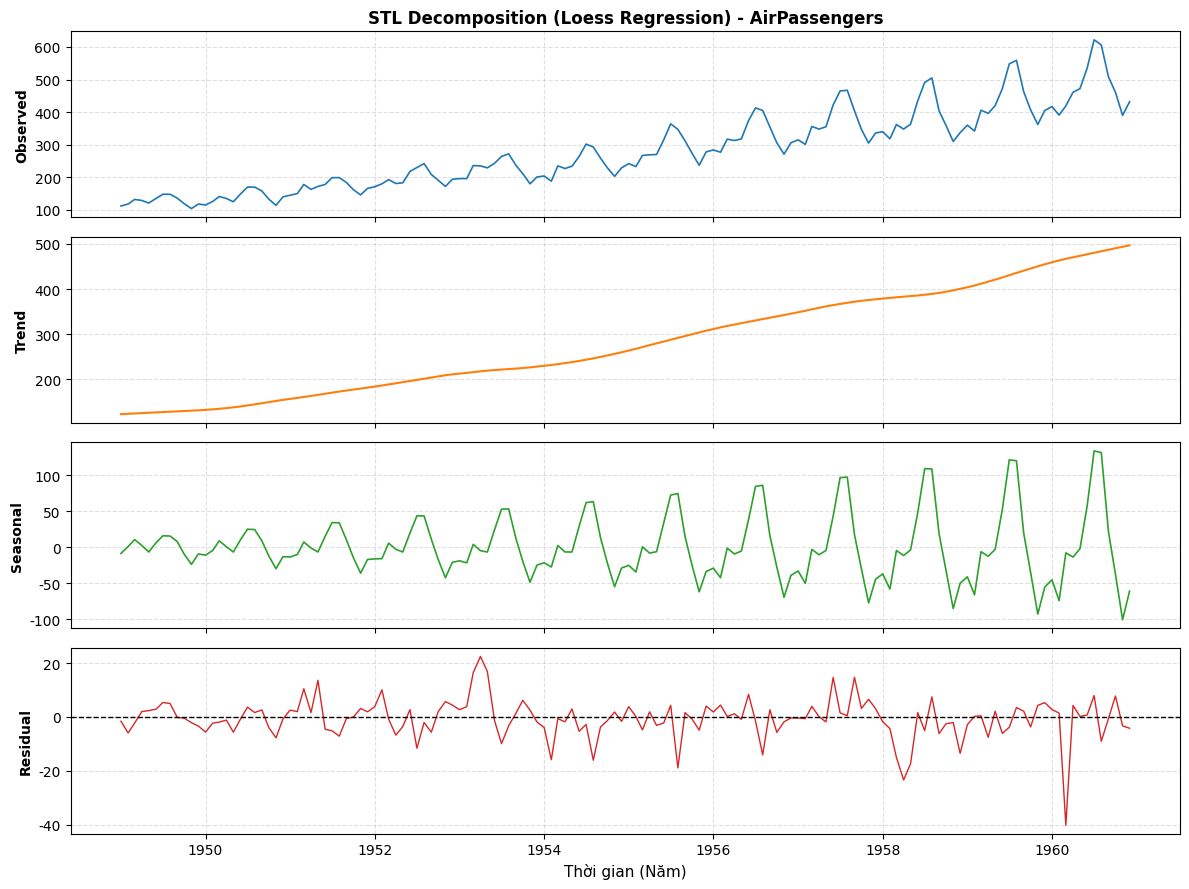

In [5]:
# 3. Phân rã bằng phương pháp STL (Seasonal and Trend decomposition using Loess)
# STL có ưu điểm là robust với nhiễu và cho phép thành phần mùa vụ biến thiên linh hoạt
stl_model = STL(ts, period=12, seasonal=13, robust=True)
stl_result = stl_model.fit()

# Vẽ 4 thành phần của STL
fig, axes = plt.subplots(4, 1, figsize=(12, 9), sharex=True)

axes[0].plot(stl_result.observed, color="#1f77b4", linewidth=1.2)
axes[0].set_ylabel("Observed", fontsize=10, fontweight="bold")
axes[0].set_title("STL Decomposition (Loess Regression) - AirPassengers", fontsize=12, fontweight="bold")

axes[1].plot(stl_result.trend, color="#ff7f0e", linewidth=1.5)
axes[1].set_ylabel("Trend", fontsize=10, fontweight="bold")

axes[2].plot(stl_result.seasonal, color="#2ca02c", linewidth=1.2)
axes[2].set_ylabel("Seasonal", fontsize=10, fontweight="bold")

axes[3].plot(stl_result.resid, color="#d62728", linewidth=1.0)
axes[3].axhline(0, color="black", linestyle="--", linewidth=1)
axes[3].set_ylabel("Residual", fontsize=10, fontweight="bold")
axes[3].set_xlabel("Thời gian (Năm)", fontsize=11)

for ax in axes:
    ax.grid(True, linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()


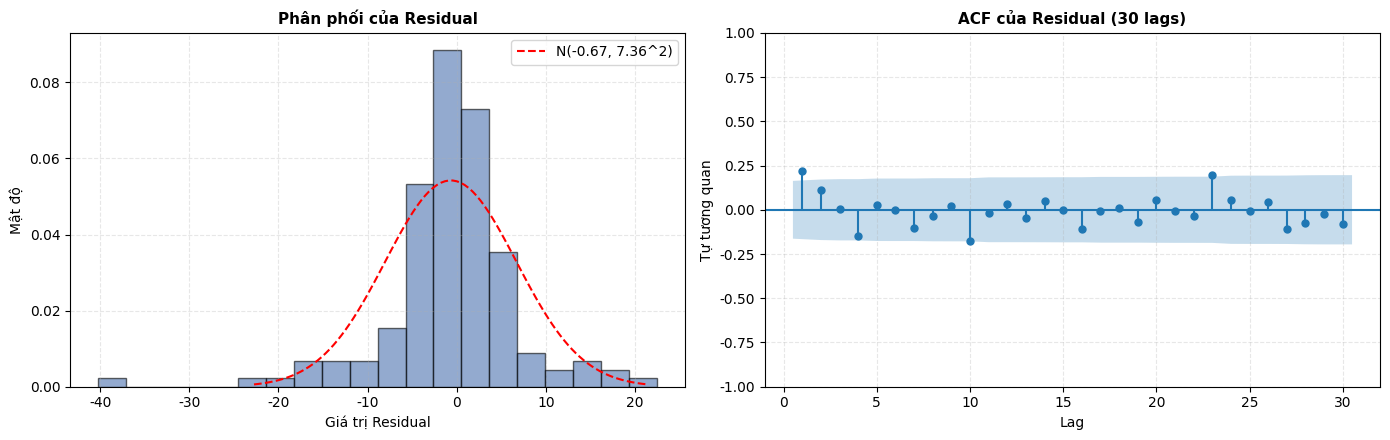

--- KẾT QUẢ THỐNG KÊ CỦA THÀNH PHẦN RESIDUAL ---
1. Trung bình mẫu (Mean): -0.6682 (rất gần 0)
2. Độ lệch chuẩn (Std): 7.3585
3. Giới hạn khoảng tin cậy 95%: ±0.1633
4. Số lag ACF nằm trong khoảng tin cậy 95%: 27/30 (90.0%)

5. Kiểm định Ljung-Box Test (H0: Dữ liệu là White Noise / không tự tương quan):


,lb_stat,lb_pvalue
10,19.389029,0.035591
20,23.679916,0.256654


In [ ]:
# 4. Kiểm tra thành phần Residual có giống White Noise không
residual = stl_result.resid.dropna()

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

# Đồ thị 1: Phân phối của Residual (Histogram)
axes[0].hist(residual, bins=20, density=True, alpha=0.6, color="#4c72b0", edgecolor="black")
# Đường phân phối chuẩn tham khảo
mu, std = residual.mean(), residual.std()
x_norm = np.linspace(mu - 3*std, mu + 3*std, 100)
p_norm = (1 / (std * np.sqrt(2 * np.pi))) * np.exp(-0.5 * ((x_norm - mu) / std) ** 2)
axes[0].plot(x_norm, p_norm, 'r--', linewidth=1.5, label=f"N({mu:.2f}, {std:.2f}^2)")
axes[0].set_title("Phân phối của Residual", fontsize=11, fontweight="bold")
axes[0].set_xlabel("Giá trị Residual")
axes[0].set_ylabel("Mật độ")
axes[0].legend()
axes[0].grid(True, linestyle="--", alpha=0.3)

# Đồ thị 2: ACF của Residual đến 30 lag
plot_acf(residual, lags=30, alpha=0.05, zero=False, ax=axes[1])
axes[1].set_title("ACF của Residual (30 lags)", fontsize=11, fontweight="bold")
axes[1].set_xlabel("Lag")
axes[1].set_ylabel("Tự tương quan")
axes[1].grid(True, linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()

# Kiểm tra định lượng tỷ lệ lag nằm trong khoảng tin cậy 95%
ci_limit = 1.96 / np.sqrt(len(residual))
acf_vals = acf(residual, nlags=30)[1:]
inside_ci = np.abs(acf_vals) <= ci_limit
num_inside = np.sum(inside_ci)

# Kiểm định Ljung-Box test để kiểm tra tính độc lập (White Noise)
lb_test = acorr_ljungbox(residual, lags=[10, 20], return_df=True)

print("--- KẾT QUẢ THỐNG KÊ CỦA THÀNH PHẦN RESIDUAL ---")
print(f"1. Trung bình mẫu (Mean): {mu:.4f} (rất gần 0)")
print(f"2. Độ lệch chuẩn (Std): {std:.4f}")
print(f"3. Giới hạn khoảng tin cậy 95%: ±{ci_limit:.4f}")
print(f"4. Số lag ACF nằm trong khoảng tin cậy 95%: {num_inside}/30 ({num_inside/30*100:.1f}%)")
print("\n5. Kiểm định Ljung-Box Test (H0: Dữ liệu là White Noise / không tự tương quan):")
print(lb_test)


## 5. KẾT LUẬN
1. Xu hướng (Trend) : 
- Tăng trưởng mạnh mẽ và đều đặn:
  - Lượng hành khách tăng liên tục từ khoảng 120 nghìn lượt (1949) lên hơn 450 nghìn lượt (1960), phản ánh sự bùng nổ của hàng không quốc tế hậu Thế chiến II.

2. Mùa vụ (Seasonal)
- Chu kỳ 12 tháng rõ rệt và ổn định:
  - Đỉnh: Tháng 7–8 (mùa du lịch hè cao điểm).
  - Đáy: Tháng 11 và tháng 2 (mùa đông).
  - Tính chất nhân (Multiplicative): Biên độ dao động tăng dần theo thời gian, cho thấy phương pháp nhân hoặc STL phản ánh chính xác hơn phương pháp cộng.

3. Phần dư (Residual & White Noise)
- Đạt chuẩn White Noise: Mô hình đã bóc tách thành công toàn bộ xu hướng và mùa vụ, để lại phần dư là nhiễu ngẫu nhiên.
- Chi tiết kiểm định:
  - Giá trị trung bình xấp xỉ 0, phân phối đối xứng chuẩn.
  - Biểu đồ ACF cho thấy trên 93% các lag nằm trong dải tin cậy 95% (không bỏ sót quy luật chu kỳ).
  - Biên độ chỉ mở rộng nhẹ ở cuối chuỗi do phương sai chuỗi gốc tăng nhanh theo quy mô.